In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, event, text
from sqlalchemy.engine import URL

ROOT = r'D:\Bluestock work\bluestock-fintech-analysis1'
PROCESSED_DIR = os.path.join(ROOT, 'data', 'processed')
REPORTS_DIR = os.path.join(ROOT, 'reports')
SQL_DIR = os.path.join(ROOT, 'sql')
DB_PATH = os.path.join(PROCESSED_DIR, 'bluestock_dw.db')

engine = create_engine(URL.create('sqlite', database=DB_PATH))

@event.listens_for(engine, 'connect')
def turn_on_foreign_keys(dbapi_connection, connection_record):
    cursor = dbapi_connection.cursor()
    cursor.execute('PRAGMA foreign_keys = ON')
    cursor.close()

In [2]:
pd.read_sql_query("""
SELECT COUNT(DISTINCT amfi_code) AS funds,
       COUNT(*)                  AS nav_rows,
       SUM(is_filled)            AS filled_rows,
       MIN(date_key)             AS first_date_key,
       MAX(date_key)             AS last_date_key
FROM fact_nav
""", engine)

,funds,nav_rows,filled_rows,first_date_key,last_date_key
0,40,64320,18320,20220103,20260529


In [3]:
sql = """
SELECT n.amfi_code, n.date_key, d.full_date, n.nav
FROM fact_nav AS n
JOIN dim_date AS d ON d.date_key = n.date_key
WHERE n.is_filled = 0
ORDER BY n.amfi_code, n.date_key
"""

nav = pd.read_sql_query(sql, engine)
nav['date'] = pd.to_datetime(nav['full_date'])

print(nav.shape)
print(nav.groupby('amfi_code').size().describe())

(46000, 5)
count      40.0
mean     1150.0
std         0.0
min      1150.0
25%      1150.0
50%      1150.0
75%      1150.0
max      1150.0
dtype: float64


In [4]:
nav['prev_nav'] = nav.groupby('amfi_code')['nav'].shift(1)
nav['daily_return'] = nav['nav'] / nav['prev_nav'] - 1
nav['days_since_prev'] = nav.groupby('amfi_code')['date'].diff().dt.days

returns = nav.dropna(subset=['daily_return']).copy()
returns['daily_return_pct'] = returns['daily_return'] * 100

print('NAV rows:', len(nav), '| funds:', nav['amfi_code'].nunique(), '| return rows:', len(returns))
assert len(nav) - nav['amfi_code'].nunique() == len(returns), 'Wrong number of return rows'

NAV rows: 46000 | funds: 40 | return rows: 45960


In [5]:
check = nav.groupby('amfi_code')['nav'].pct_change()
print('Same as pct_change:', np.allclose(returns['daily_return'], check.loc[returns.index]))

Same as pct_change: True


In [7]:
assert returns['daily_return'].notnull().all(), 'Missing return'
assert np.isfinite(returns['daily_return']).all(), 'Infinite return'
assert (returns['daily_return'] > -1).all(), 'A return is -100% or lower'
assert (returns['days_since_prev'] >= 1).all(), 'Dates are not in order'

print('Valid')

Valid


In [8]:
r = returns['daily_return_pct']

print(r.describe().round(3))
print()
print('Skew:', round(r.skew(), 2), '| Kurtosis:', round(r.kurt(), 2))
print('Share of days exactly 0 (%):', round((r == 0).mean() * 100, 2))
print('Share of days beyond 3 standard deviations (%):',
      round((((r - r.mean()) / r.std()).abs() > 3).mean() * 100, 2), '(a bell curve gives 0.27)')
print('Days with a move above 5% in size:', (r.abs() > 5).sum())

count    45960.000
mean         0.063
std          1.029
min         -5.810
25%         -0.504
50%          0.034
75%          0.632
max          6.471
Name: daily_return_pct, dtype: float64

Skew: 0.04 | Kurtosis: 1.37
Share of days exactly 0 (%): 0.01
Share of days beyond 3 standard deviations (%): 0.96 (a bell curve gives 0.27)
Days with a move above 5% in size: 9


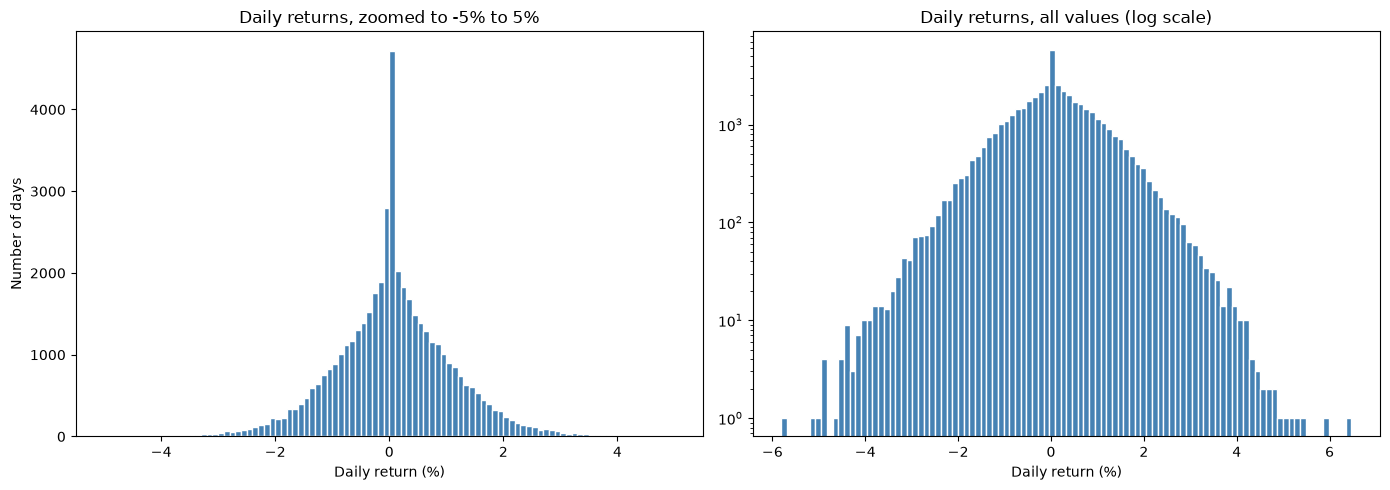

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(r, bins=100, range=(-5, 5), color='steelblue', edgecolor='white')
axes[0].set_title('Daily returns, zoomed to -5% to 5%')
axes[0].set_xlabel('Daily return (%)')
axes[0].set_ylabel('Number of days')

axes[1].hist(r, bins=100, color='steelblue', edgecolor='white')
axes[1].set_yscale('log')
axes[1].set_title('Daily returns, all values (log scale)')
axes[1].set_xlabel('Daily return (%)')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'daily_return_histograms.png'))
plt.show()

In [10]:
funds = pd.read_sql_query(
    'SELECT amfi_code, scheme_name, category, sub_category, plan FROM dim_fund', engine)

by_fund = returns.groupby('amfi_code').agg(
    days=('daily_return', 'count'),
    mean_pct=('daily_return_pct', 'mean'),
    std_pct=('daily_return_pct', 'std'),
    min_pct=('daily_return_pct', 'min'),
    max_pct=('daily_return_pct', 'max'),
    zero_share=('daily_return', lambda s: (s == 0).mean()),
    big_moves=('daily_return_pct', lambda s: (s.abs() > 5).sum()),
    skew=('daily_return_pct', 'skew'),
    kurt=('daily_return_pct', 'kurt'),
).round(3).reset_index()

by_fund = by_fund.merge(funds, on='amfi_code', how='left')
by_fund = by_fund.sort_values('std_pct', ascending=False)

by_fund[['amfi_code', 'scheme_name', 'category', 'days', 'mean_pct', 'std_pct',
         'min_pct', 'max_pct', 'zero_share', 'big_moves']]

,amfi_code,scheme_name,category,days,mean_pct,std_pct,min_pct,max_pct,zero_share,big_moves
4,101207,ABSL Small Cap Fund - Regular - Growth,Equity,1149,0.042,1.625,-5.185,5.485,0.001,2
11,118634,Nippon India Small Cap Fund - Regular - Growth,Equity,1149,0.071,1.590,-5.810,5.930,0.001,3
21,119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,1149,0.120,1.584,-4.518,6.471,0.000,2
17,119095,Axis Small Cap Fund - Regular - Growth,Equity,1149,0.018,1.579,-4.837,4.311,0.000,0
22,119599,SBI Small Cap Fund - Direct Plan - Growth,Equity,1149,0.020,1.572,-4.543,5.332,0.000,2
39,149324,DSP Small Cap Fund - Regular - Growth,Equity,1149,0.119,1.565,-4.887,4.849,0.000,0
16,119094,Axis Midcap Fund - Regular - Growth,Equity,1149,0.103,1.223,-4.075,4.159,0.000,0
25,120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,1149,0.116,1.215,-3.842,4.081,0.000,0
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,1149,0.108,1.193,-4.424,4.195,0.000,0
33,125498,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Equity,1149,0.048,1.156,-4.522,3.619,0.000,0


          count   mean    std    min    max
category                                   
Debt       6894  0.023  0.177 -0.888  0.884
Equity    39066  0.070  1.114 -5.810  6.471


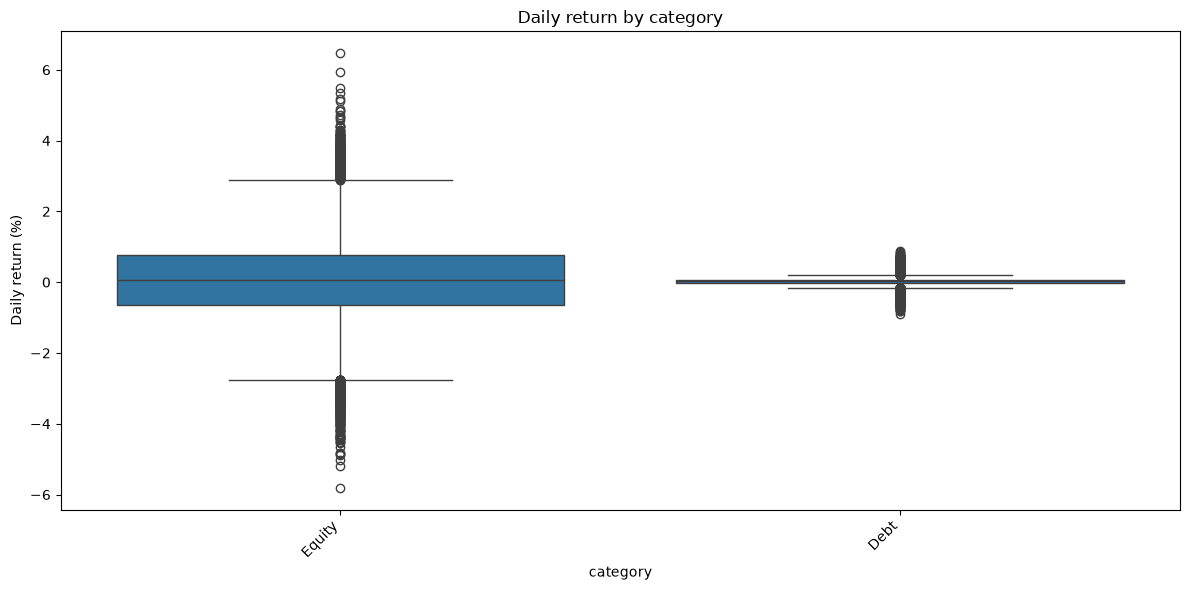

In [11]:
returns_cat = returns.merge(funds[['amfi_code', 'category']], on='amfi_code', how='left')

print(returns_cat.groupby('category')['daily_return_pct']
      .agg(['count', 'mean', 'std', 'min', 'max']).round(3))

plt.figure(figsize=(12, 6))
sns.boxplot(data=returns_cat, x='category', y='daily_return_pct', showfliers=True)
plt.xticks(rotation=45, ha='right')
plt.title('Daily return by category')
plt.ylabel('Daily return (%)')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'daily_return_by_category.png'))
plt.show()

          count   mean    std    min    max
category                                   
Debt       6894  0.023  0.177 -0.888  0.884
Equity    39066  0.070  1.114 -5.810  6.471


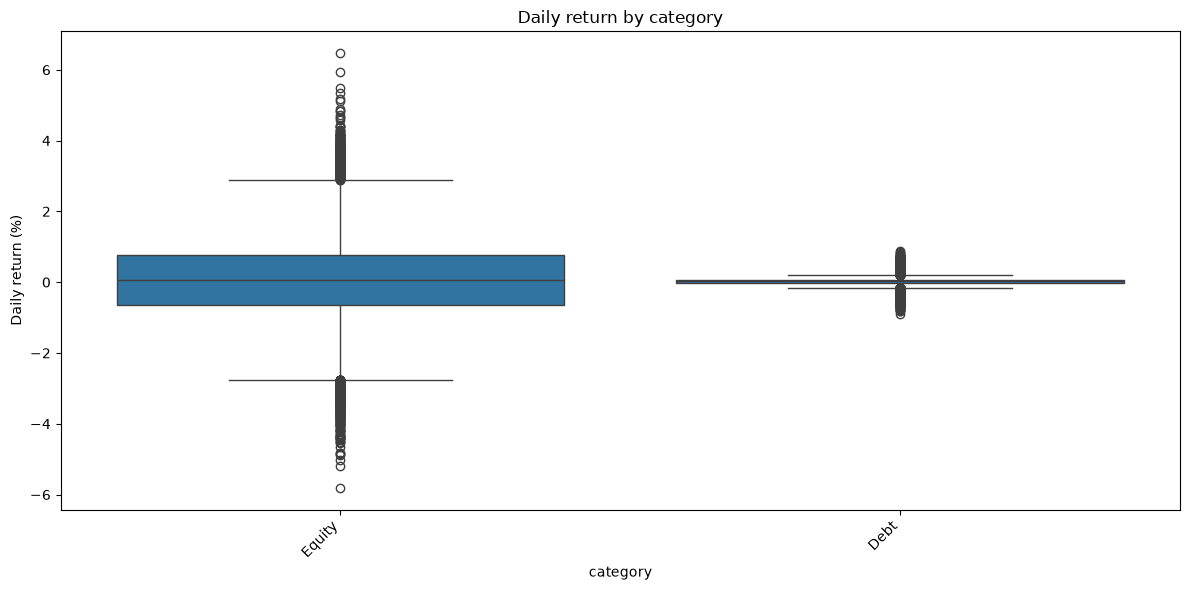

In [15]:
returns_cat = returns.merge(funds[['amfi_code', 'category']], on='amfi_code', how='left')

print(returns_cat.groupby('category')['daily_return_pct']
      .agg(['count', 'mean', 'std', 'min', 'max']).round(3))

plt.figure(figsize=(12, 6))
sns.boxplot(data=returns_cat, x='category', y='daily_return_pct', showfliers=True)
plt.xticks(rotation=45, ha='right')
plt.title('Daily return by category')
plt.ylabel('Daily return (%)')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'daily_return_by_category.png'))
plt.show()

In [16]:
BIG_MOVE_PCT = 5

big = returns[returns['daily_return_pct'].abs() > BIG_MOVE_PCT].copy()
big['funds_with_big_move_same_day'] = big.groupby('date_key')['amfi_code'].transform('count')
big = big.merge(funds[['amfi_code', 'scheme_name', 'category']], on='amfi_code', how='left')

cols = ['scheme_name', 'category', 'full_date', 'days_since_prev',
        'daily_return_pct', 'funds_with_big_move_same_day']

print('Days with a move above', BIG_MOVE_PCT, '% in size:', len(big))
print()
print('Largest falls')
print(big.sort_values('daily_return_pct').head(10)[cols].round(2))
print()
print('Largest rises')
print(big.sort_values('daily_return_pct', ascending=False).head(10)[cols].round(2))

Days with a move above 5 % in size: 9

Largest falls
                                      scheme_name category   full_date  \
2  Nippon India Small Cap Fund - Regular - Growth   Equity  2022-06-24   
0          ABSL Small Cap Fund - Regular - Growth   Equity  2023-03-22   
3  Nippon India Small Cap Fund - Regular - Growth   Equity  2023-03-01   
5      SBI Small Cap Fund - Regular Plan - Growth   Equity  2022-01-10   
8       SBI Small Cap Fund - Direct Plan - Growth   Equity  2024-01-17   
7       SBI Small Cap Fund - Direct Plan - Growth   Equity  2023-01-10   
1          ABSL Small Cap Fund - Regular - Growth   Equity  2024-05-01   
4  Nippon India Small Cap Fund - Regular - Growth   Equity  2024-03-19   
6      SBI Small Cap Fund - Regular Plan - Growth   Equity  2024-04-15   

   days_since_prev  daily_return_pct  funds_with_big_move_same_day  
2              1.0             -5.81                             1  
0              1.0             -5.18                             1  

In [17]:
print(returns['days_since_prev'].value_counts().sort_index())

long_gap = returns[returns['days_since_prev'] > 7]
print()
print('Returns that cover a gap of more than 7 days:', len(long_gap))
print(long_gap.groupby('amfi_code').size())

days_since_prev
1.0    36800
3.0     9160
Name: count, dtype: int64

Returns that cover a gap of more than 7 days: 0
Series([], dtype: int64)


In [19]:
with open(os.path.join(SQL_DIR, '02_fact_daily_return.sql'), 'r', encoding='utf-8') as f:
    ddl = f.read()

conn = sqlite3.connect(DB_PATH)
conn.execute('PRAGMA foreign_keys = ON')
conn.executescript(ddl)
conn.commit()
conn.close()

pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", engine)

,name
0,dim_date
1,dim_fund
2,fact_aum
3,fact_daily_return
4,fact_nav
5,fact_performance
6,fact_transactions


In [20]:
fact_daily_return = pd.DataFrame({
    'amfi_code': returns['amfi_code'],
    'date_key': returns['date_key'],
    'days_since_prev': returns['days_since_prev'].astype(int),
    'daily_return': returns['daily_return'],
})

with engine.begin() as conn:
    conn.execute(text('DELETE FROM fact_daily_return'))
    fact_daily_return.to_sql('fact_daily_return', conn, if_exists='append', index=False, chunksize=50_000)

with engine.connect() as conn:
    n_db = conn.execute(text('SELECT COUNT(*) FROM fact_daily_return')).scalar()
    db_sum = conn.execute(text('SELECT SUM(daily_return) FROM fact_daily_return')).scalar()
    fk_problems = conn.execute(text('PRAGMA foreign_key_check')).fetchall()

print('Rows in the database:', n_db, '| rows in the DataFrame:', len(fact_daily_return))
print('Sum of returns matches:', np.isclose(db_sum, fact_daily_return['daily_return'].sum()))
print('Foreign key problems:', len(fk_problems))

Rows in the database: 45960 | rows in the DataFrame: 45960
Sum of returns matches: True
Foreign key problems: 0


In [21]:
sql_check = """
SELECT amfi_code, date_key,
       nav / LAG(nav) OVER (PARTITION BY amfi_code ORDER BY date_key) - 1 AS sql_return
FROM fact_nav
WHERE is_filled = 0
"""

sql_returns = pd.read_sql_query(sql_check, engine).dropna()
merged = sql_returns.merge(fact_daily_return, on=['amfi_code', 'date_key'], how='outer', indicator=True)

print(merged['_merge'].value_counts())
print('Same values:', np.allclose(merged['sql_return'], merged['daily_return']))

_merge
both          45960
left_only         0
right_only        0
Name: count, dtype: int64
Same values: True


In [22]:
lines = [
    '# Daily returns summary',
    '',
    f'- Funds: {returns["amfi_code"].nunique()}. Return rows: {len(returns)}. Dates: {returns["full_date"].min()} to {returns["full_date"].max()}.',
    '- Formula: daily_return = nav_t / nav_(t-1) - 1, as a fraction. Only real NAV days were used (is_filled = 0).',
    f'- Overall (percent): mean {r.mean():.3f}, std {r.std():.3f}, min {r.min():.2f}, max {r.max():.2f}.',
    f'- Skew {r.skew():.2f}. Kurtosis {r.kurt():.2f}.',
    f'- Days exactly 0: {(r == 0).mean() * 100:.2f}%.',
    f'- Days with a move above {BIG_MOVE_PCT}% in size: {len(big)}.',
    f'- Returns that cover a gap of more than 7 days: {len(long_gap)}.',
    f'- Database table fact_daily_return: {n_db} rows. Row counts, sums, and a SQL LAG check all match.',
    '',
    '## Assumptions to confirm with my manager',
    '- Filled weekend and holiday rows were not used. They would give fake returns of 0%.',
    '- Returns that span a long gap were kept. The column days_since_prev shows the gap.',
    f'- A move above {BIG_MOVE_PCT}% in one day is a "big move". This limit is my choice.',
]

summary_text = '\n'.join(lines)

with open(os.path.join(REPORTS_DIR, 'daily_returns_summary.md'), 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(summary_text)

# Daily returns summary

- Funds: 40. Return rows: 45960. Dates: 2022-01-04 to 2026-05-29.
- Formula: daily_return = nav_t / nav_(t-1) - 1, as a fraction. Only real NAV days were used (is_filled = 0).
- Overall (percent): mean 0.063, std 1.029, min -5.81, max 6.47.
- Skew 0.04. Kurtosis 1.37.
- Days exactly 0: 0.01%.
- Days with a move above 5% in size: 9.
- Returns that cover a gap of more than 7 days: 0.
- Database table fact_daily_return: 45960 rows. Row counts, sums, and a SQL LAG check all match.

## Assumptions to confirm with my manager
- Filled weekend and holiday rows were not used. They would give fake returns of 0%.
- Returns that span a long gap were kept. The column days_since_prev shows the gap.
- A move above 5% in one day is a "big move". This limit is my choice.
